# Quantum Key Distribution Simulator
This notebook's objectif is to showcase the results from the simulator that I have written in Java.

All the simulation files are in this [Github Repository](https://github.com/Haydara1/Quantum-Cryptography-Simulator.git). 

For more information about BB84, you can check this [wikipedia article](https://fr.wikipedia.org/wiki/Protocole_BB84).

For more information regarding how the simulator works, check out this [blog](https://haydara1.github.io/posts/Physics/BB84.html).

## The BB84 Simulator:
**Objectif:** Does the Quantum Bit Error Rate (QBER) converge towards the theoretical prediction: 
$$
\text{QBER} = \frac{p_{eve}}{4}
$$

Where $ p_{eve} $ is the intercept probability.

In [12]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Import the .csv file.

The file is constructed using the following way:

- Construct an array of intercept probabilities (from 0 to 1, incrementing by 0.1 per step)
- Run the experiment for each probability a 100 times.
- For each experiment, use 10 thousands Qubits.

In [13]:
df = pd.read_csv("bb84_results.csv")

df.head()

,experiment_id,eve_probability,qubits_sent,sifted_bits,sample_bits,errors,qber,theoretical_qber,key_bits,accepted
0,1,0.0,10000,5016,2508,0,0.0,0.0,2508,True
1,2,0.0,10000,5058,2529,0,0.0,0.0,2529,True
2,3,0.0,10000,4929,2464,0,0.0,0.0,2465,True
3,4,0.0,10000,4949,2474,0,0.0,0.0,2475,True
4,5,0.0,10000,5036,2518,0,0.0,0.0,2518,True


Here you can see the first five rows of the file:

- Experiment ID: a unique ID for each experiment.
- Eve probability: the intercept probability.
- Qubits sent: constant equal to 10,000.
- Sifted bits: number of matching bits between Alice and Bob.
- Sample bits: number of sifted bits randomly selected to check the error rate.
- Errors: number of errors found in the samples.
- QBER: $ \text{Errors} / \text{Sample bits} $
- Theoretical QBER: $ p / 4 $
- Key Bits: number of sifter bits left after removing the sample.
- Accepted: whether the protocol accepts the key or not.

### QBER experimental vs QBER theoretical:

In [14]:
# Group by intercept probability

summary = (
    df.groupby("eve_probability")
    .agg(
        mean_qber=("qber", "mean"),
        std_qber=("qber", "std"),
        experiment_count=("qber", "count"),
        mean_sifted_bits=("sifted_bits", "mean"),
        acceptance_rate=("accepted", "mean")
    )
    .reset_index()
)

summary["standard_error"] = (
    summary["std_qber"] / np.sqrt(summary["experiment_count"])
)

summary["theoretical_qber"] = (
    summary["eve_probability"] / 4
)

display(summary)

,eve_probability,mean_qber,std_qber,experiment_count,mean_sifted_bits,acceptance_rate,standard_error,theoretical_qber
0,0.0,0.000000,0.000000,100,5004.34,1.00,0.000000,0.000
1,0.1,0.024698,0.002711,100,5008.42,1.00,0.000271,0.025
2,0.2,0.049309,0.004274,100,4997.13,1.00,0.000427,0.050
3,0.3,0.074112,0.005715,100,5000.17,1.00,0.000572,0.075
4,0.4,0.100893,0.005368,100,4997.08,0.94,0.000537,0.100
5,0.5,0.126151,0.006238,100,4996.60,0.00,0.000624,0.125
6,0.6,0.149413,0.008339,100,4993.80,0.00,0.000834,0.150
7,0.7,0.173154,0.006568,100,4992.75,0.00,0.000657,0.175
8,0.8,0.200807,0.008240,100,4998.54,0.00,0.000824,0.200
9,0.9,0.224534,0.008337,100,5002.23,0.00,0.000834,0.225


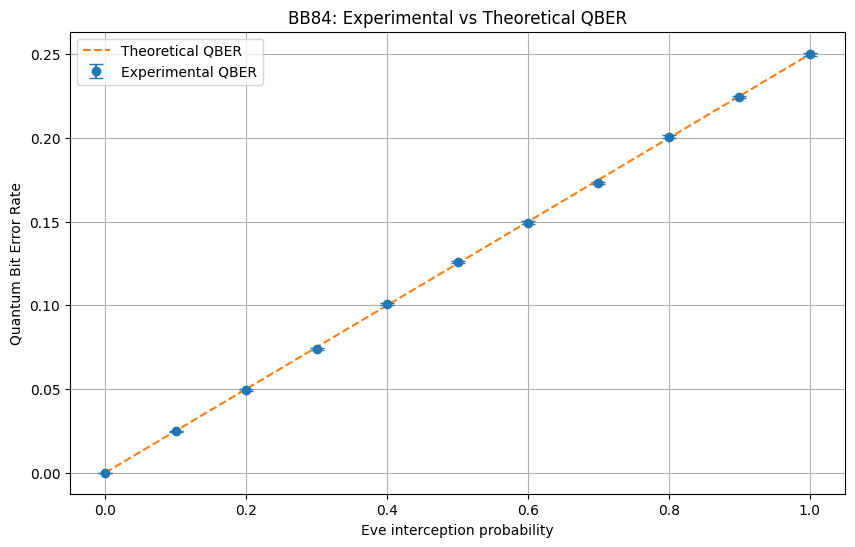

In [15]:
#Plot the QBER:

plt.figure(figsize=(10, 6))

plt.errorbar(
    summary["eve_probability"],
    summary["mean_qber"],
    yerr=summary["standard_error"],
    fmt="o",
    capsize=5,
    label="Experimental QBER"
)

plt.plot(
    summary["eve_probability"],
    summary["theoretical_qber"],
    linestyle="--",
    label="Theoretical QBER"
)

plt.xlabel("Eve interception probability")
plt.ylabel("Quantum Bit Error Rate")
plt.title("BB84: Experimental vs Theoretical QBER")

plt.legend()
plt.grid(True)
plt.show()

In the above plot we can clearly see that the experimental QBER is very close to the theoretical QBER, even though we are only performing 100 experiments per probability.

We can check the deviation for each probability:

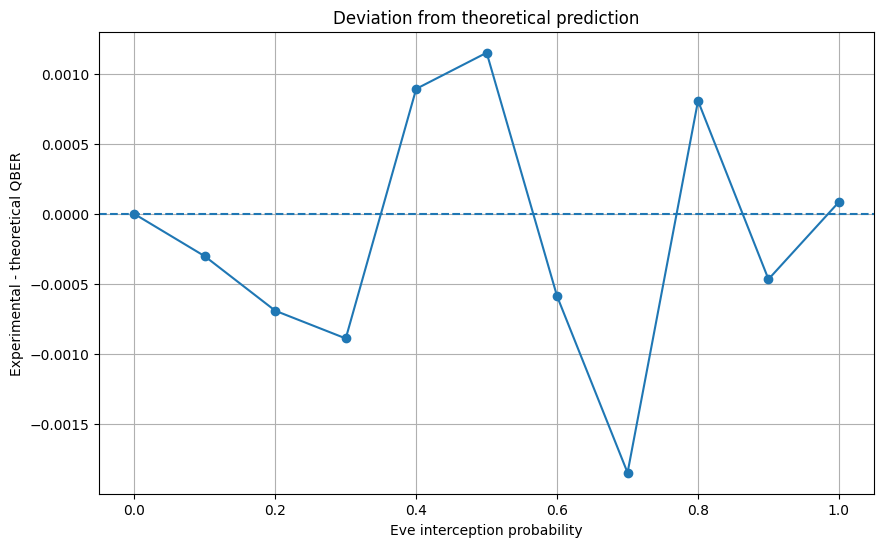

In [16]:
summary["deviation"] = (
    summary["mean_qber"] - summary["theoretical_qber"]
)

plt.figure(figsize=(10, 6))

plt.axhline(0, linestyle="--")
plt.plot(
    summary["eve_probability"],
    summary["deviation"],
    marker="o"
)

plt.xlabel("Eve interception probability")
plt.ylabel("Experimental - theoretical QBER")
plt.title("Deviation from theoretical prediction")
plt.grid()
plt.show()

### Acceptance rate:
Knowing that the threshhold is fixed to 11%.

In [18]:
acceptance_summary = (
    df.groupby("eve_probability")
    .agg(
        accepted_experiments=("accepted", "sum"),
        total_experiments=("accepted", "count")
    )
    .reset_index()
)

acceptance_summary["acceptance_rate"] = (
    acceptance_summary["accepted_experiments"]
    / acceptance_summary["total_experiments"]
)

display(acceptance_summary)



,eve_probability,accepted_experiments,total_experiments,acceptance_rate
0,0.0,100,100,1.00
1,0.1,100,100,1.00
2,0.2,100,100,1.00
3,0.3,100,100,1.00
4,0.4,94,100,0.94
5,0.5,0,100,0.00
6,0.6,0,100,0.00
7,0.7,0,100,0.00
8,0.8,0,100,0.00
9,0.9,0,100,0.00


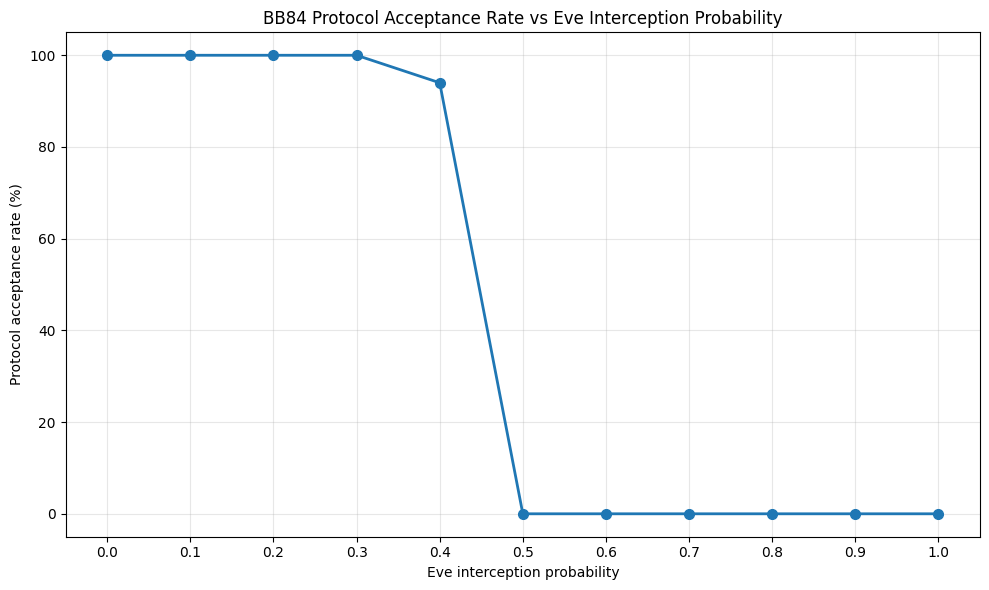

In [19]:

plt.figure(figsize=(10, 6))

plt.plot(
    acceptance_summary["eve_probability"],
    acceptance_summary["acceptance_rate"] * 100,
    marker="o",
    linewidth=2,
    markersize=7
)

plt.xlabel("Eve interception probability")
plt.ylabel("Protocol acceptance rate (%)")
plt.title("BB84 Protocol Acceptance Rate vs Eve Interception Probability")

plt.ylim(-5, 105)
plt.xticks(np.arange(0, 1.01, 0.1))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
